# EN.605.631 — Simulation with R (Chapter 10)

### Student Shell Notebook — Scaffolding, Hints, and TODOs

**Instructions:**
- This notebook is a scaffold. Fill in the TODOs, replace placeholders, and add discussion where prompted.
- You may use either **base R** or **tidyverse**. The scaffolding shows one possible structure.
- Keep your random seeds as 631 where asked so results are reproducible.

> Tip: As you implement each method, make small test runs (e.g., `n=1e4`) to check logic and visuals before scaling up.


In [1]:
## --- Setup (libraries, helpers, seed) ---
## You may add/remove libraries as needed.
## Keep a global seed for reproducibility in figures and benchmarks.

set.seed(631)
suppressPackageStartupMessages({
  library(ggplot2)
  library(dplyr)
  library(purrr)
  library(tidyr)
  library(broom)
  library(microbenchmark)
})

## Helper: generic Wald-type 95% CI for a sample mean
mean_ci <- function(x, level = 0.95) {
  n <- length(x)
  m <- mean(x)
  s <- sd(x)
  alpha <- 1 - level
  z <- qnorm(1 - alpha/2)
  half <- z * s / sqrt(n)
  c(lower = m - half, mean = m, upper = m + half)
}

var_ci <- function(x) {
  n <- length(x)
  s2 <- var(x)
  m4 <- mean((x - mean(x))^4)
  se <- sqrt(max(0, m4 - s2^2) / n)
  z <- qnorm(0.975)
  c(lower = max(0, s2 - z * se), variance = s2, upper = s2 + z * se)
}

## Helper: CI for an acceptance rate (binomial proportion)
prop_ci <- function(k, n, level = 0.95) {
  ## Wilson CI (more stable than Wald at edges)
  alpha <- 1 - level
  z <- qnorm(1 - alpha/2)
  phat <- k / n
  denom <- 1 + (z^2)/n
  center <- (phat + (z^2)/(2*n)) / denom
  half <- (z * sqrt( (phat*(1-phat)/n) + (z^2)/(4*n^2) )) / denom
  c(lower = center - half, p = phat, upper = center + half)
}

## Helper: overlay empirical CDF vs target CDF (piecewise or provided function)
plot_ecdf_vs_target <- function(x, F_target, title = "ECDF vs Target CDF") {
  df <- data.frame(x = sort(x), ecdf = ecdf(x)(sort(x)))
  xs <- pretty(range(x), n = 200)
  df2 <- data.frame(x = xs, F = F_target(xs))
  ggplot() +
    geom_step(data = df, aes(x = x, y = ecdf), direction = "hv") +
    geom_line(data = df2, aes(x = x, y = F), linewidth = 0.7, linetype = 2) +
    labs(title = title, y = "Cumulative probability", x = "x") +
    theme_minimal()
}


## 📚 Problem 1 — Inverse transform: custom continuous & Weibull (12 pts)

### 1.1 Custom piecewise CDF
Target CDF:
- For $x\in(-3,0)$: $F(x)=\tfrac{1}{2}+\tfrac{x}{6}$
- For $x\in[0,4]$: $F(x)=\tfrac{1}{2}+\tfrac{x^2}{32}$

**TODOs:**
1. Derive the inverse CDF $F^{-1}(u)$ in closed form for $u\in(0,1)$.
2. Implement a generator that maps uniforms to samples from this distribution.
3. Validate via ECDF overlay with the target CDF.

> **Hint:** Ensure $F$ is continuous at 0 and strictly increasing over the support; check which $u$ slice corresponds to which branch.


$F(X)=P(X\leq x)=\begin{cases}0, &x\le-3, \\\tfrac12+x/6, &-3<x<0, \\\tfrac12+x^2/32, &0\le x\le 4, \\1, &x>4\end{cases}$

The branches meet at $x=0$ when $F(0)=1/2$

The negative x branch is on $0\lt u\lt 1/2$ and the non-negative x branch is on $1/2\le u\lt1$

On each branch, solve $u=F(x)$ for $x$:

$u=\frac12+\frac{x}{6}$

$u-\frac12=\frac{x}{6}$

$6\left(u-\frac12\right)=x$

$x=6u-3$

$F^{-1}(u)=6u-3$ for $0<u<\tfrac12$



$u=\frac12+\frac{x^2}{32}$

$u-\frac12=\frac{x^2}{32}$

$32\left(u-\frac12\right)=x^2$

$x=\pm\sqrt{32\left(u-\frac12\right)}$

$F^{-1}(u)=\sqrt{32\left(u-\frac12\right)}$ for $\tfrac12\le u<1$

Combine for $F^{-1}(u)=\begin{cases}6u-3,&0<u<1/2,\\\sqrt{32(u-1/2)},&1/2\le u<1\end{cases}$

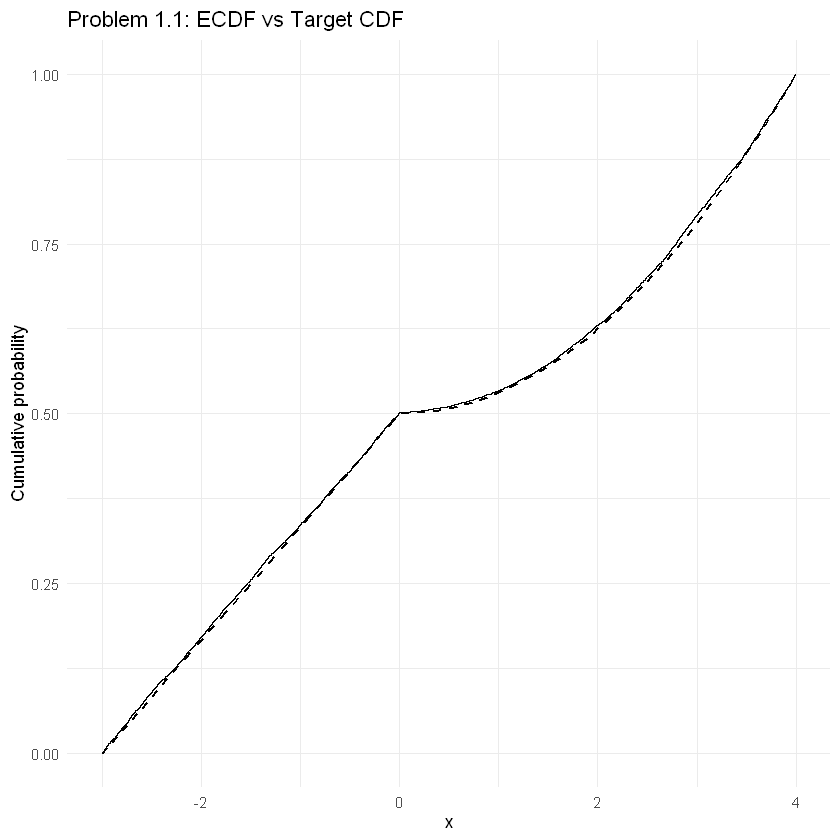

In [2]:
## --- Problem 1.1: Custom piecewise via inverse transform ---
## Derive F^{-1} on paper first. Then implement below.

Finv_piecewise <- function(u) {
  ## INPUT: u in (0,1) (vectorized)
  ## TODO: implement the piecewise inverse.
  ## HINTS:
  ## - Find the u-range for x in (-3,0): plug x=-3 and x -> 0^- into F(x).
  ## - For the right branch, solve u = 1/2 + x^2/32 for x in [0,4].
  out <- numeric(length(u))
  ## Example structure (replace with correct logic):
  u_left_max <- 1/2
  idx_left <- u < u_left_max
  out[idx_left] <- 6 * u[idx_left] - 3
  out[!idx_left] <- sqrt(32 * (u[!idx_left] - 1/2))
  out
}

r_piecewise <- function(n) {
  u <- runif(n)
  Finv_piecewise(u)
}

## Target CDF function for visualization (vectorized)
F_target_piecewise <- function(x) {
  y <- numeric(length(x))
  y[x < -3] <- 0
  y[x >= -3 & x < 0] <- 1/2 + x[x >= -3 & x < 0]/6
  y[x >= 0 & x <= 4] <- 1/2 + (x[x >= 0 & x <= 4]^2)/32
  y[x > 4] <- 1
  y
}

## VALIDATION PLOT (after implementing Finv_piecewise)
set.seed(631); x <- r_piecewise(1e4)
plot_ecdf_vs_target(x, F_target_piecewise, title = "Problem 1.1: ECDF vs Target CDF")

### 1.2 Weibull via inverse transform
Given CDF $F(t) = 1 - \exp(-\alpha t^{\beta})$.

**TODOs:**
1. Implement an inverse-transform generator.
2. Compare to `rweibull` for two $(\alpha,\beta)$ pairs using QQ-plots.
3. For each generator, estimate mean/variance with 95% CI and compare to analytic values.

> **Hint:** Solve $U=1-\exp(-\alpha T^{\beta})$ for $T$.


For $F(t)=1-e^{-\alpha t^\beta}$

$U=F(t)=1-e^{-\alpha T^\beta}$

$U = 1-e^{-\alpha T^{\beta}}$

$1-U = e^{-\alpha T^{\beta}}$

$\ln(1-U) = -\alpha T^{\beta}$

$-\frac{\ln(1-U)}{\alpha} = T^{\beta}$

$T=\left(-\frac{\ln(1-U)}{\alpha}\right)^{1/\beta}$

For `rweibull` shape $k=\beta$ and scale $\lambda=\alpha^{-1/\beta}$

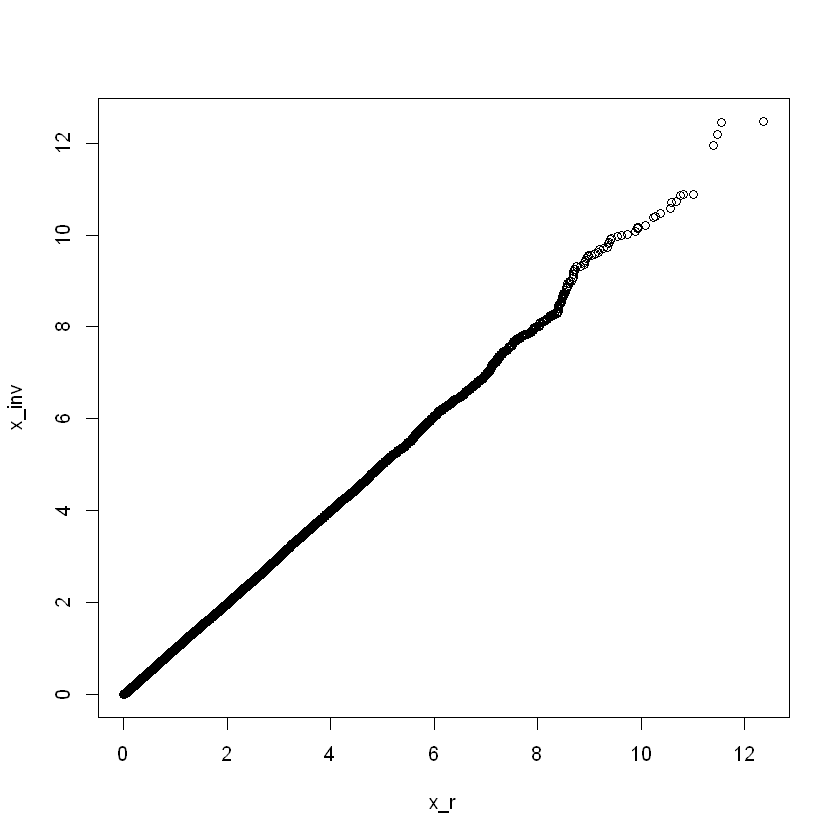

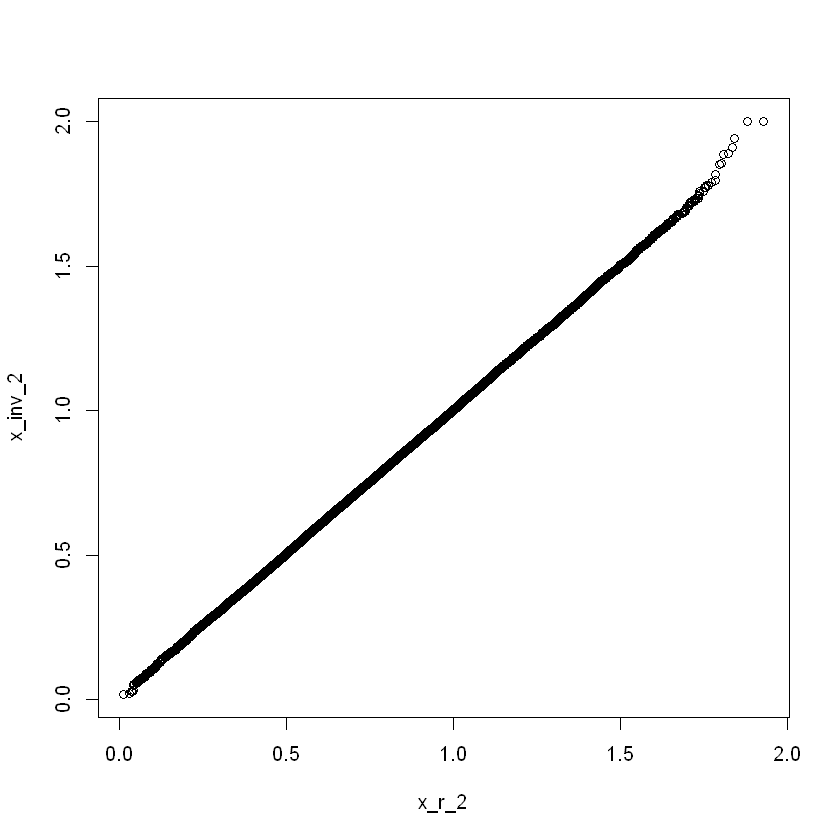

In [3]:
## --- Problem 1.2: Weibull via inverse transform ---
rweibull_inv <- function(n, alpha, beta) {
  ## TODO: implement inverse sampling: T = ...
  u <- runif(n)
  t <- NA_real_
  ## t <- ((-log(1-u))/alpha)^(1/beta)  # replace alpha/beta symbols as needed
  t <- ((-log(1-u))/alpha)^(1/beta)
  t
}

## QQ-plot comparison to base R rweibull
## Example pairs: (alpha,beta) = (0.5, 1.2), (1.5, 3)
set.seed(631)
n <- 5e4
x_inv <- rweibull_inv(n, alpha=0.5, beta=1.2)
x_r   <- rweibull(n, shape=1.2, scale=(0.5)^(-1/1.2))  # check parameterization carefully
# qplot(sample = x_inv) + stat_qq(aes(sample = x_r))  # or use qqplot(x_r, x_inv, ...)

x_inv_2 <- rweibull_inv(n, alpha=1.5, beta=3)
x_r_2   <- rweibull(n, shape=3, scale=(1.5)^(-1/3))
# qplot(sample = x_inv_2) + stat_qq(aes(sample = x_r_2))

qqplot(x_r, x_inv)
qqplot(x_r_2, x_inv_2)

$E[T]=\lambda\Gamma(1+1/\beta)$

$\mathrm{Var}(T)=\lambda^2\left[\Gamma(1+2/\beta)-\Gamma(1+1/\beta)^2\right]$

In [4]:
## Analytic mean/var of Weibull(shape=k, scale=λ):
## E[X] = λ Γ(1 + 1/k), Var[X] = λ^2 (Γ(1 + 2/k) - Γ(1 + 1/k)^2)
## Map (alpha, beta) to (λ, k) carefully; document your mapping below.
weibull_analytic <- function(alpha, beta) {
  scale <- alpha^(-1 / beta)
  mu <- scale * gamma(1 + 1 / beta)
  sigma2 <- scale^2 * (gamma(1 + 2 / beta) - gamma(1 + 1 / beta)^2)
  c(mean = mu, variance = sigma2)
}

compare_weibull <- function(x, alpha, beta, method) {
  analytic <- weibull_analytic(alpha, beta)
  m_ci <- mean_ci(x)
  v_ci <- var_ci(x)

  data.frame(
    Method = method,
    Alpha = alpha,
    Beta = beta,
    Mean = mean(x),
    Mean_Lower = m_ci["lower"],
    Mean_Upper = m_ci["upper"],
    Mean_Analytic = analytic["mean"],
    Variance = var(x),
    Var_Lower = v_ci["lower"],
    Var_Upper = v_ci["upper"],
    Var_Analytic = analytic["variance"],
    row.names = NULL
  )
}

## TODO: Implement mean/var estimate with CI and compare to analytic formulas.
set.seed(631)
results <- rbind(
  compare_weibull(x_inv, 0.5, 1.2, "rweibull_inv"),
  compare_weibull(x_r, 0.5, 1.2, "rweibull"),
  compare_weibull(x_inv_2, 1.5, 3, "rweibull_inv"),
  compare_weibull(x_r_2, 1.5, 3, "rweibull")
)
print(results, digits = 5)

        Method Alpha Beta    Mean Mean_Lower Mean_Upper Mean_Analytic Variance
1 rweibull_inv   0.5  1.2 1.67168    1.65940    1.68397       1.67606 1.964268
2     rweibull   0.5  1.2 1.67794    1.66568    1.69019       1.67606 1.954590
3 rweibull_inv   1.5  3.0 0.78223    0.77976    0.78470       0.78009 0.079530
4     rweibull   1.5  3.0 0.77756    0.77508    0.78005       0.78009 0.080204
  Var_Lower Var_Upper Var_Analytic
1   1.92491  2.003630     1.967558
2   1.91641  1.992771     1.967558
3   0.07861  0.080450     0.080384
4   0.07928  0.081129     0.080384


The plots show close agreement between the empirical samples and rweibull samples for pairs with some sampling error in the tails.

The empirical means and variances are close to the analytical values. Most analytical values fall within the 95% confidence intervals.

## 📚 Problem 2 — Rejection sampling and acceptance rates (12 pts)

### 2.1 Two-sided exponential-like target
Target density:
- $f(x)\propto e^{2x}$ on $(-\infty,0)$, and $f(x)\propto e^{-2x}$ on $(0,\infty)$.

**TODOs:**
1. Propose a convenient $g$ (e.g., a symmetric Laplace or a mixture of exponentials). Derive a valid bound $c$ s.t. $f(x)\le c\,g(x)$.
2. Implement rejection sampling and estimate acceptance rate with CI.
3. Verify with a density overlay.

> **Hint:** The target is proportional to a **Laplace(0, b)** with an appropriate rate; leverage that structure.


Normalized target density is $f(x)=e^{-2|x|}$ for $-\infty<x<\infty$

Let $g(x)=\tfrac12e^{-|x|}$

$\frac{f(x)}{g(x)}=2e^{-|x|}\le c=2$

$P(\text{accept}\mid Y=y)=e^{-|y|}$

$P(\text{accept})=1/c=1/2=0.5$

A Laplace(0,1/2) proposal would accept all samples but Laplace(0,1) proposal actually rejects samples. Proposition 2.2 proves the accepted observations have density $f$ and the number of trials has geometric mean $c$

Warning message:
"The dot-dot notation (`..density..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(density)` instead."


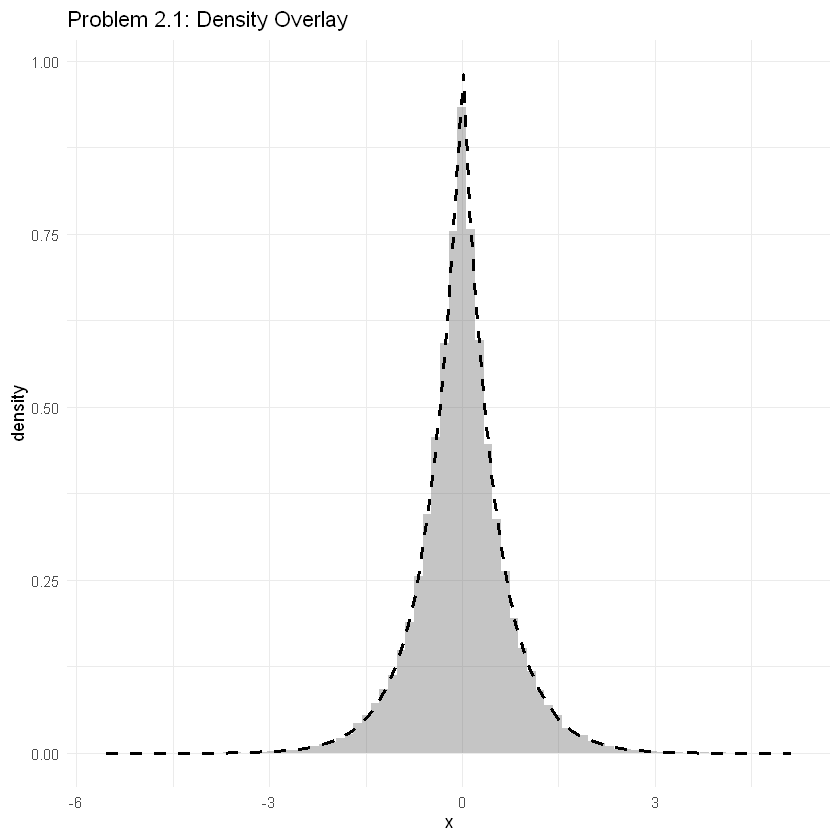

In [5]:
set.seed(631)

## --- Problem 2.1: Rejection sampler for two-sided exponential-like ---
r_target_21 <- function(n) {
  ## TODO: Implement rejection sampling for the specified target.
  ## Choose g and c; return a vector of n samples.
  ## Track number of proposals to compute acceptance rate.
  x <- numeric(n)
  proposals <- 0
  accepted <- 0
  while (accepted < n) {
    y <- rexp(1) * sample(c(-1, 1), 1)
    proposals <- proposals + 1
    if (runif(1) < exp(-abs(y))) { # P(accept | Y=y)
      accepted <- accepted + 1
      x[accepted] <- y
    }
  }
  attr(x, "proposals") <- proposals
  attr(x, "accepted_all") <- accepted
  return(x)
}

## After implementing, produce a density overlay:
x <- r_target_21(5e4)
df <- data.frame(x=x)
ggplot(df, aes(x)) +
  geom_histogram(aes(y=..density..), bins=80, alpha=0.35) +
  stat_function(fun = function(z) {  ## normalized target density
    exp(-2 * abs(z))
  }, 
  linewidth=0.9, linetype=2) + theme_minimal() + labs(title = "Problem 2.1: Density Overlay")


In [6]:
accepted <- attr(x, "accepted_all")
proposed <- attr(x, "proposals")
ci <- prop_ci(accepted, proposed)

results <- data.frame(
  proposals = proposed,
  accepted = accepted,
  acceptance_rate = ci["p"],
  CI_lower = ci["lower"],
  CI_upper = ci["upper"],
  analytical_rate = 1/2
)
print(results, row.names = FALSE, digits = 4)

 proposals accepted acceptance_rate CI_lower CI_upper analytical_rate
    100091    50000          0.4995   0.4964   0.5026             0.5


### 2.2 Beta-like target with uniform proposal
Target density: $f(x)=60x^3(1-x)^2$ on $(0,1)$.

**TODOs:**
1. Implement rejection sampling using $g(x)=1$ on $(0,1)$ (uniform proposal). Derive the bound $c$.
2. Compare acceptance efficiency to sampling via `rbeta(shape1=4, shape2=3)`.

> **Hint:** The given density is a Beta$(4,3)$ form up to normalization. Identify the mode to get a tight $c$ for the uniform proposal.


Target density: $f(x)=60x^3(1-x)^2$ on $(0,1)$

$g(x)=1$

Find the max of $\frac{f(x)}{g(x)}$

$f'(x)=\frac{d}{dx}f(x)=\frac{d}{dx}\left[60x^3(1-x)^2\right]=60\left[3x^2(1-x)^2+x^3\cdot2(1-x)(-1)\right]$

$=60\left[3x^2(1-x)^2-2x^3(1-x)\right]=60x^2(1-x)\left[3(1-x)-2x\right]=60x^2(1-x)(3-3x-2x)$

$=60x^2(1-x)(3-5x)$

critical points $x=0, x=\frac35, x=1$

$f(0)=60(0)^3(1-0)^2=0$

$f(1)=60(1)^3(1-1)^2=0$

$f\left(\frac35\right)=60\left(\frac35\right)^3\left(1-\frac35\right)^2=60\left(\frac{27}{125}\right)\left(\frac4{25}\right)=\frac{6480}{3125}=2.0736$

max at $x=\frac35$

$c=f(\frac35)=60(\frac35)^3(\frac25)^2=2.0736$

$P(\text{accept}\mid Y=y)=\frac{f(y)}{cg(y)}$

acceptance rate $P(\text{accept})=\frac1c$

In [7]:
## --- Problem 2.2: Rejection with uniform proposal ---
r_beta_like_reject <- function(n) {
  ## TODO: implement rejection for f(x)=60 x^3(1-x)^2 on (0,1) using g(x)=1
  x <- numeric(n)
  proposals <- 0
  accepted <- 0
  c <- 2.0736
  while (accepted < n) {
    y <- runif(1)
    p <- 60 * y^3 * (1-y)^2 / c
    proposals <- proposals + 1

    if (runif(1) < p) {
      accepted <- accepted + 1
      x[accepted] <- y
    }
  }
  attr(x, "proposals") <- proposals
  attr(x, "accepted_all") <- accepted
  return(x)
}


## Efficiency comparison
set.seed(631)
n <- 1e5
x_rej <- r_beta_like_reject(n)
x_rbeta <- rbeta(n, shape1=4, shape2=3)
## TODO: compute acceptance rate for rejection and compare with trivial 100% for rbeta; brief discussion.
acceptance_rate <- n / attr(x_rej, "proposals")
acceptance_rate
1/2.0736

[1] 0.4826418

[1] 0.4822531

The theoretical acceptance rate is $1/2.0736=0.4823$

My simulated acceptance rate is 0.4826 which is very close to the theoretical value

This means rejection sampling requires generating 2.07 proposals per accepted sample

## 📚 Problem 3 — Simulating discrete laws: Geometric, Poisson, Binomial (10 pts)

### 3.1 Geometric$(p)$ via log formula
Use one uniform per variate. Validate with pmf overlay for $p\in\{0.2, 0.5\}$.


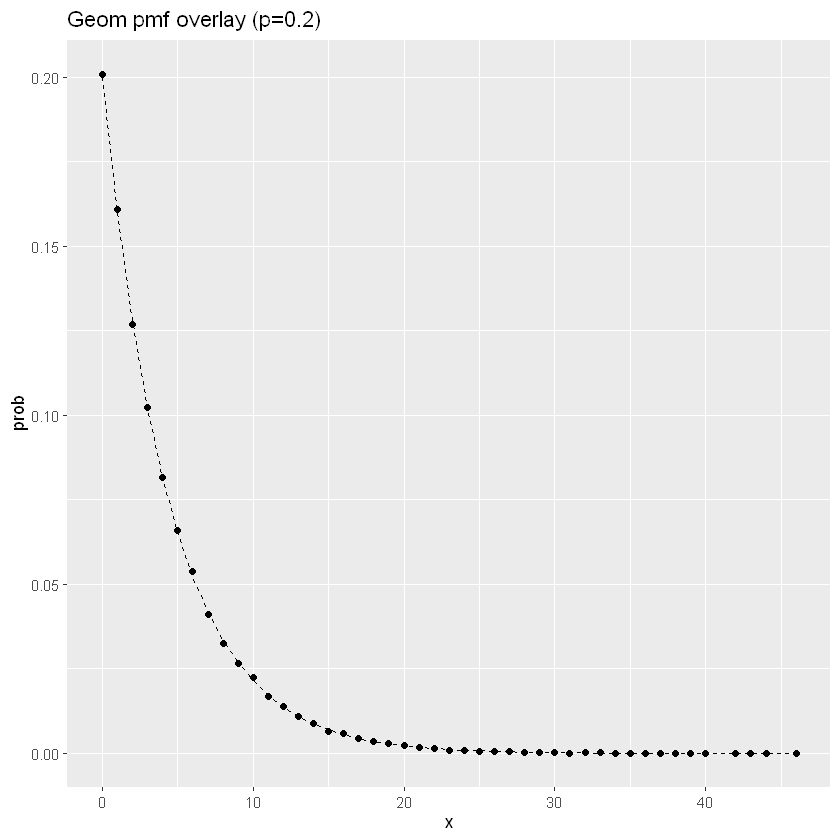

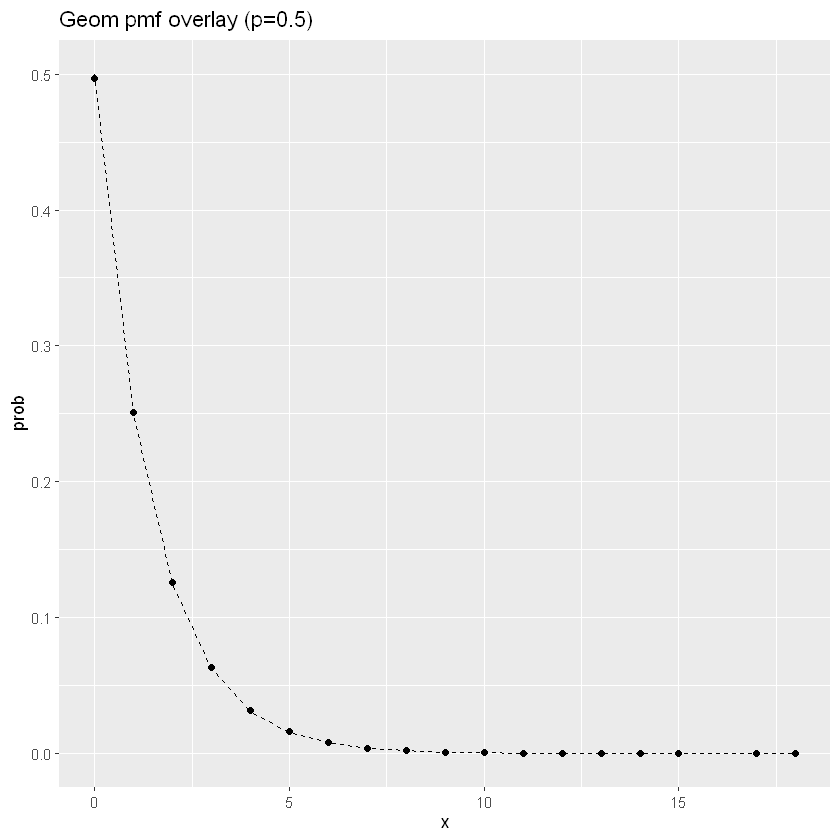

In [8]:
## --- Problem 3.1: Geometric via inverse/log ---
rgeom_log <- function(n, p) {
  ## Support convention: number of failures before first success (0,1,2,...) as in R's rgeom.
  ## Formula: X = floor( log(1-U) / log(1-p) )
  ## TODO: implement and verify
  u <- runif(n)
  return(floor(log(1 - u) / log(1 - p)))
}

## Validation: overlay empirical pmf vs theoretical dgeom
set.seed(631); n <- 1e5; pvals <- c(0.2, 0.5)
for (p in pvals) {
  x <- rgeom_log(n, p)
  tab <- as.data.frame(table(x)) |>
    mutate(x = as.integer(as.character(x)), p_emp = Freq/sum(Freq), p_theo = dgeom(x, prob = p))
  print(ggplot(tab, aes(x)) + geom_point(aes(y=p_emp)) + geom_line(aes(y=p_theo), linetype=2) +
    labs(title=paste0("Geom pmf overlay (p=", p, ")"), y="prob"))
}

### 3.2 Poisson$(\lambda)$ via product-of-uniforms
Compare to `rpois`.


In [9]:
## --- Problem 3.2: Poisson via product-of-uniforms ---
rpois_prod <- function(n, lambda) {
  ## Knuth's method: multiply uniforms until product < e^{-lambda}.
  ## TODO: implement efficiently for vector of size n (loop acceptable).
  x <- numeric(n)
  for (i in 1:n) {
    product <- 1
    count <- 0
    while (product >= exp(-lambda)) {
      product <- product * runif(1)
      count <- count + 1
    }
    x[i] <- count - 1
  }
  x
}

## Compare to rpois
set.seed(631); x1 <- rpois_prod(2e4, lambda=3); x2 <- rpois(2e4, lambda=3)
## TODO: QQ-plot or side-by-side summaries
data.frame(Method = c("Product method", "rpois", "Theory"), 
           Mean = c(mean(x1), mean(x2), 3), Var = c(var(x1), var(x2), 3))

Method,Mean,Var
<chr>,<dbl>,<dbl>
Product method,2.98440,2.971305
rpois,3.00195,2.944193
Theory,3.00000,3.000000


### 3.3 Binomial$(n,p)$ via summing Bernoullis
Confirm mean/variance and runtime scaling vs `rbinom` for large $n$.


In [10]:
## --- Problem 3.3: Binomial via sum of Bernoulli ---
rbinom_sum <- function(N, n, p) {
  ## Generate N iid Binomial(n,p) by summing n Bernoulli(p) for each draw.
  ## TODO: vectorized or loop; compare runtime to rbinom for large n.
  x <- numeric(N)
  for (i in 1:N) {
    x[i] <- sum(runif(n) < p)
  }
  x
}

## Validation & scaling study
set.seed(631)
N <- 5e3; n <- 1000; p <- 0.3
x_sum <- rbinom_sum(N, n, p)
x_r   <- rbinom(N, n, p)
## TODO: compare means/vars and microbenchmark
data.frame(Method = c("Bernoulli sum", "rbinom", "Theory"),
           Mean = c(mean(x_sum), mean(x_r), n * p), Variance = c(var(x_sum), var(x_r), n * p * (1 - p)))

for (trials in c(1000, 10000, 100000)) {
  sum_time <- system.time(rbinom_sum(1000, trials, p))["elapsed"]
  rbinom_time <- system.time(rbinom(1000, trials, p))["elapsed"]
  print(data.frame(Trials = trials, Sum_seconds = unname(sum_time), rbinom_seconds = unname(rbinom_time)))
}

Method,Mean,Variance
<chr>,<dbl>,<dbl>
Bernoulli sum,299.9134,209.5178
rbinom,300.2526,218.3969
Theory,300.0000,210.0000


  Trials Sum_seconds rbinom_seconds
1   1000        0.02              0
  Trials Sum_seconds rbinom_seconds
1  10000        0.09              0
  Trials Sum_seconds rbinom_seconds
1  1e+05        0.82              0


## 📚 Problem 4 — Normal generation: Box–Muller & polar (efficiency) (12 pts)

**TODOs:**
1. Implement Box–Muller and Marsaglia's polar method.
2. Validate with QQ-plots and KS tests; report p-values.
3. Benchmark vs `rnorm` for generating $10^6$ normals; report timing and throughput.

> **Hint:** Keep the pairwise outputs from each transform to avoid discarding work.


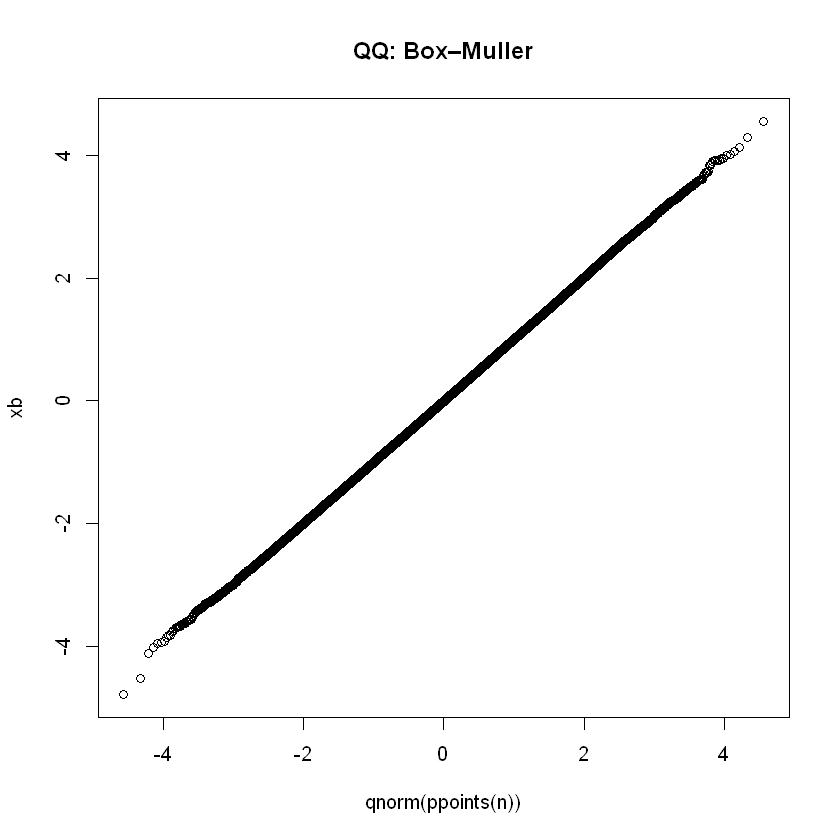

[1] 0.2530426

[1] 0.2228246

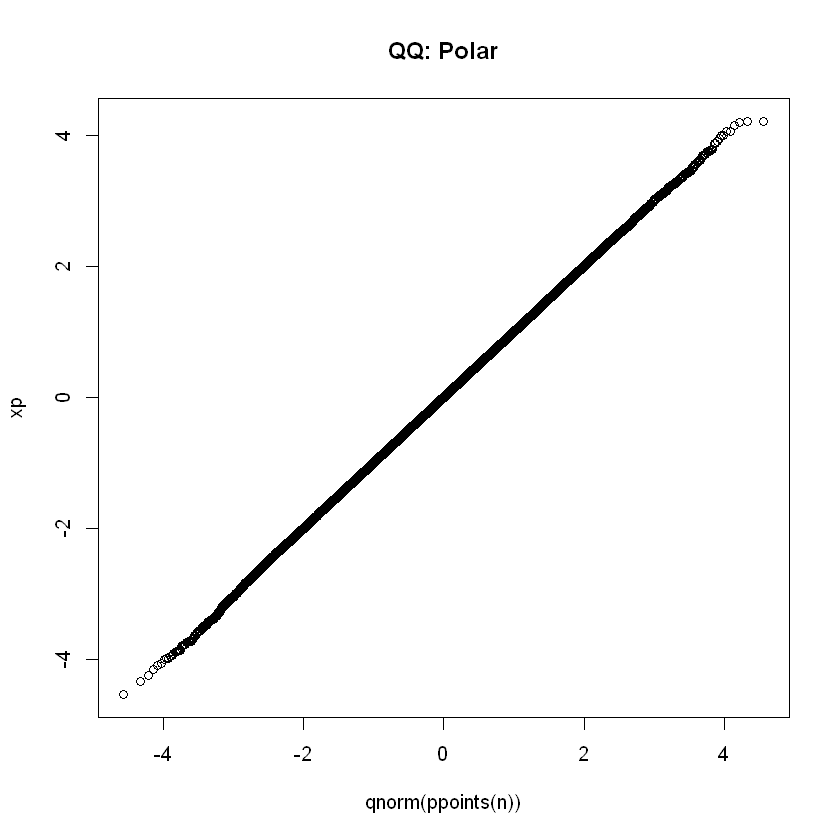

In [11]:
## --- Problem 4: Normal generators ---
rnorm_box_muller <- function(n) {
  ## TODO: Implement; return n N(0,1)
  pairs <- ceiling(n / 2)
  u1 <- runif(pairs)
  u2 <- runif(pairs)
  r <- sqrt(-2 * log(u1))
  angle <- 2 * pi * u2

  x <- c(r * cos(angle), r * sin(angle))
  x[1:n]
}

rnorm_polar <- function(n) {
  ## TODO: Implement Marsaglia polar; return n N(0,1)
  x <- numeric(0)
  while (length(x) < n) {
    pairs <- ceiling((n - length(x)) / 2 * 1.4) + 10
    v1 <- runif(pairs, -1, 1)
    v2 <- runif(pairs, -1, 1)
    s <- v1^2 + v2^2
    keep <- (s > 0) & (s < 1)
    factor <- sqrt(-2 * log(s[keep]) / s[keep])
    x <- c(x, v1[keep] * factor, v2[keep] * factor)
  }
  x[1:n]
}

## Validation: QQ and KS
set.seed(631); n <- 2e5
xb <- rnorm_box_muller(n); xp <- rnorm_polar(n)
qqplot(qnorm(ppoints(n)), xb, main="QQ: Box–Muller")
qqplot(qnorm(ppoints(n)), xp, main="QQ: Polar")
ks.test(xb, "pnorm")$p.value; ks.test(xp, "pnorm")$p.value

In [12]:
## TODO: compute throughput (values/sec) and discuss accuracy vs speed.
set.seed(631)

## Benchmarks (adjust n if needed for your machine)
nbench <- 1e6
microbenchmark(
  bm = rnorm_box_muller(nbench),
  pl = rnorm_polar(nbench),
  rn = rnorm(nbench),
  times = 3
)

N <- 1000000
bench <- microbenchmark(Box_Muller = rnorm_box_muller(N), Polar = rnorm_polar(N), Rnorm = rnorm(N), times = 3)
seconds <- tapply(bench$time / 1e9, bench$expr, median)
data.frame(Method = names(seconds), Seconds = as.numeric(seconds),
          Values_per_second = as.numeric(nbench / seconds))

data.frame(Method = c("Box-Muller", "Polar", "Analytical"), Mean = c(mean(xb), mean(xp), 0), Variance = c(var(xb), var(xp), 1))

expr,time
<fct>,<dbl>
bm,62758600
rn,27792702
pl,53025500
pl,131333001
bm,132448000
bm,60007501
pl,53320001
rn,28703601
rn,105527401


Method,Seconds,Values_per_second
<chr>,<dbl>,<dbl>
Box_Muller,0.1389083,7198994
Polar,0.0532410,18782517
Rnorm,0.0265945,37601758


Method,Mean,Variance
<chr>,<dbl>,<dbl>
Box-Muller,-0.001274391,1.002800
Polar,0.003156860,1.000261
Analytical,0.000000000,1.000000


The sample means and variances are all close to the theoretical values 0 and 1. Each QQ plot shows points close to $y=x$ in agreement with the normal distribution. P-values above 0.05 means the test does not reject normality at the 5% level and below 0.05 may occasionally occur even for a correct generator. 

The benchmark reports the median elapsed time from three runs and throughput $10^6$ (normal values per second). A larger throughput means the method is faster. 

+ Box-Muller is the slowest and has the lowest throughput
+ the polar method avoids sine and cosine but rejects some proposals
+ rnorm() is best optimized

## 📚 Problem 5 — Random permutations & assignment (10 pts)

### 5.1 Fisher–Yates shuffle
Implement and test uniformity for small $n$.



	Chi-squared test for given probabilities

data:  counts
X-squared = 3.3752, df = 5, p-value = 0.6423



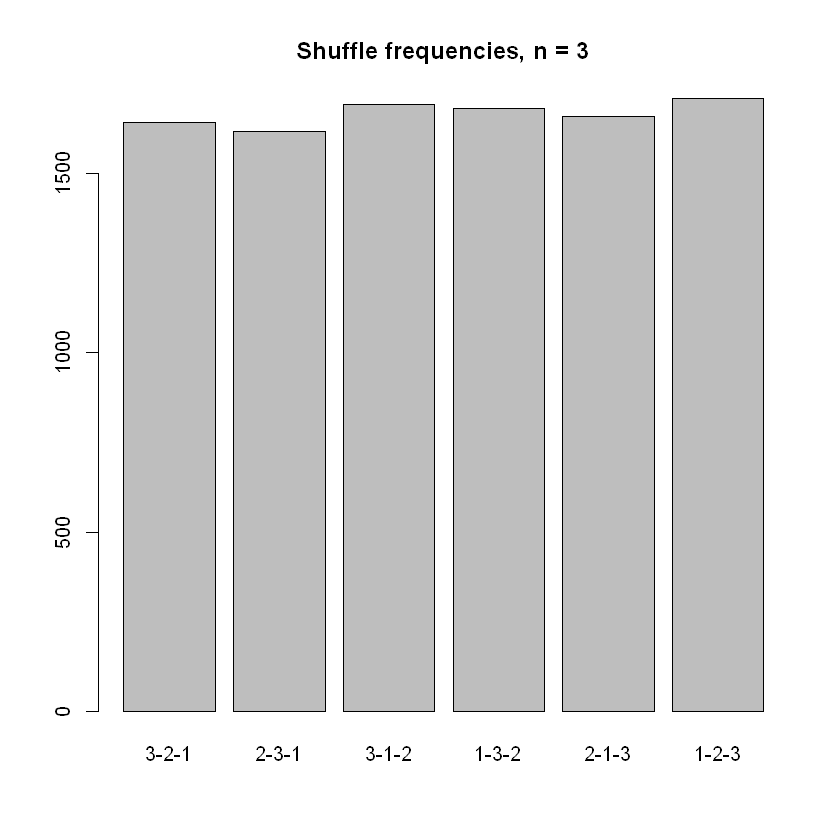


	Chi-squared test for given probabilities

data:  counts
X-squared = 14.97, df = 23, p-value = 0.8957



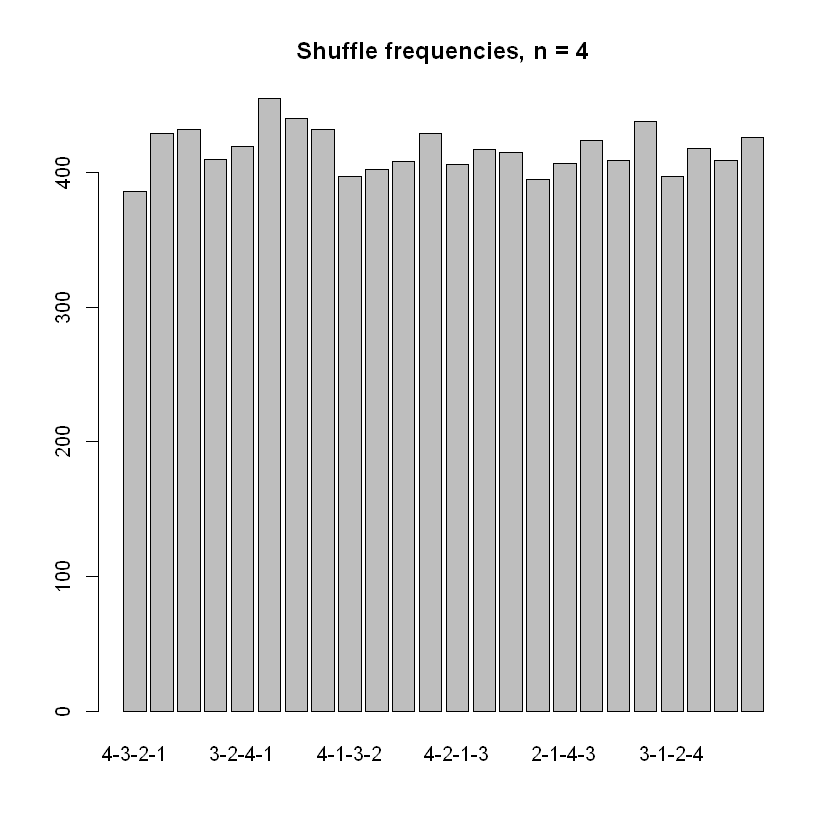

In [13]:
## --- Problem 5.1: Fisher–Yates shuffle ---
fy_shuffle <- function(x) {
  ## In-place Fisher–Yates (Knuth) shuffle
  n <- length(x)
  for (i in seq(n, 2)) {
    j <- sample.int(i, 1)
    tmp <- x[i]; x[i] <- x[j]; x[j] <- tmp
  }
  x
}

## Unit test idea for small n: empirical uniformity over all permutations
## TODO: For n in {3,4} enumerate all permutations, run many shuffles, compare frequencies.
set.seed(631)
for (n in c(3, 4)) {
  # enumerate all permutations
  grid <- expand.grid(rep(list(1:n), n))
  grid <- grid[apply(grid, 1, function(row) {
    length(unique(row))
  } == n), ]

  permutations <- apply(grid, 1, paste, collapse = "-")
  shuffles <- replicate(10000, paste(fy_shuffle(1:n), collapse = "-"))
  counts <- table(factor(shuffles, levels = permutations))

  # frequencies
  barplot(counts, main = paste("Shuffle frequencies, n =", n))

  # chi-squared test
  print(chisq.test(counts))
}

$p\gt 0.05$ so there is no statistically significant evidence against uniformity

### 5.2 Random assignment to 3 arms (40/40/40)
Use the shuffle to permute indices 1:120 and map blocks to arms.


In [14]:
## --- Problem 5.2: Random assignment ---
assign_3arms <- function(n = 120, sizes = c(40,40,40)) {
  stopifnot(sum(sizes) == n)
  idx <- fy_shuffle(1:n)
  arms <- rep(NA_character_, n)
  cuts <- cumsum(sizes)
  arms[idx[1:cuts[1]]] <- "A"
  arms[idx[(cuts[1]+1):cuts[2]]] <- "B"
  arms[idx[(cuts[2]+1):cuts[3]]] <- "C"
  arms
}

## Validation: verify counts are 40/40/40
set.seed(8)
arms <- assign_3arms()
table(arms)

arms
 A  B  C 
40 40 40 

## 📚 Problem 6 — Variance reduction: antithetic & conditioning (π estimation) (12 pts)

Quarter circle estimator of $\pi$ on $[0,1]^2$.


$est
[1] 3.13584

$se
[1] 0.007361959

$ci
[1] 3.121411 3.150269

$est
[1] 3.149375

$se
[1] 0.003963864

$ci
[1] 3.141606 3.157144

$est
[1] 3.14129

$se
[1] 0.002089913

$ci
[1] 3.137194 3.145386



Method,Estimate,SE,CI_Lower,CI_Upper,Empirical_Variance,VRF
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Baseline,3.135840,0.007361959,3.121411,3.150269,4.606981e-05,1.00000
Conditioning,3.149375,0.003963864,3.141606,3.157144,1.938860e-05,2.37613
Antithetic,3.141290,0.002089913,3.137194,3.145386,3.947224e-06,11.67145


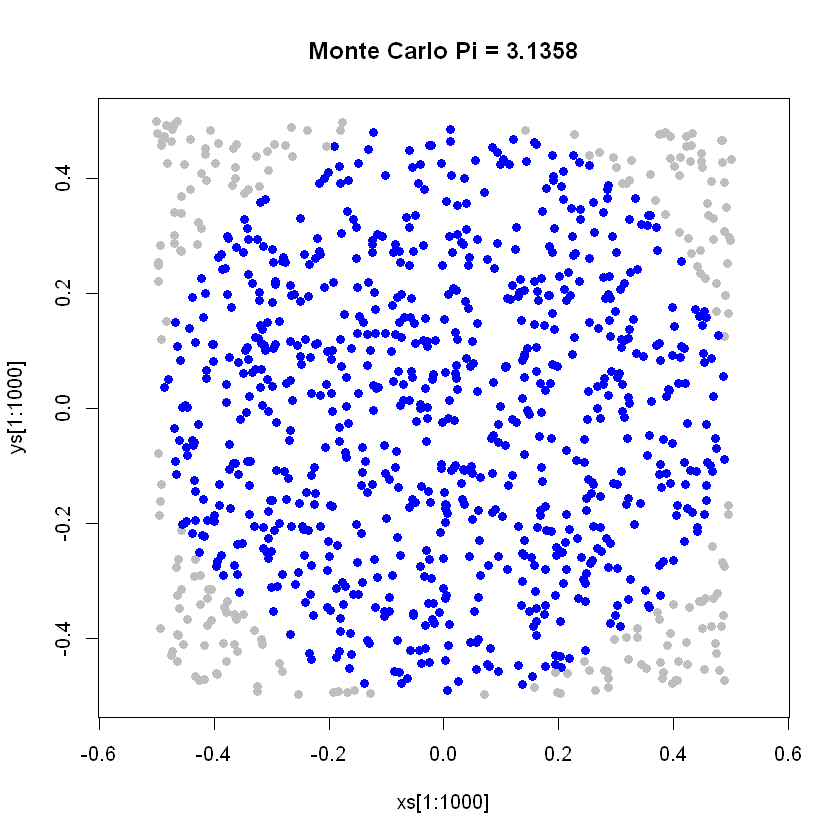

In [15]:
## --- Problem 6: π estimation ---
pi_baseline <- function(n, plot) {
  ## TODO: Monte Carlo with indicator I(X^2+Y^2 <= 1); return list(est, se, ci)
  xs <- runif(n, min=-0.5, max=0.5)
  ys <- runif(n, min=-0.5, max=0.5)
  in.circle <- xs^2 + ys^2 <= 0.5^2
  pi <- 4 * sum(in.circle) / n
  se <- 4 * sd(as.numeric(in.circle)) / sqrt(n)
  ci <- pi + c(-1, 1) * 1.96 * se
  if (plot) {
    plot(xs[1:1000], ys[1:1000],
      col=ifelse(in.circle[1:1000], "blue", "grey"),
      pch=16, asp=1,
      main=paste("Monte Carlo Pi =", round(pi, 4)))
  }
  list(est=pi, se=se, ci=ci)
}

pi_conditioning <- function(n) {
  ## TODO: Use E[I | X] = sqrt(1 - X^2) to reduce variance; return list(est, se, ci)
  xs <- runif(n, min=-0.5, max=0.5)
  conditioned <- 8 * sqrt(0.25 - xs^2)
  pi <- mean(conditioned)
  se <- sd(conditioned) / sqrt(n)
  ci <- pi + c(-1, 1) * 1.96 * se
  list(est=pi, se=se, ci=ci)
}

pi_antithetic <- function(n) {
  ## TODO: Use antithetic pairs (U,1-U) to reduce variance further; return list(est, se, ci)
  u <- runif(n/2)
  a <- sqrt(1 - u^2)
  b <- sqrt(1 - (1-u)^2)
  antithetic <- 4 * (a+b) / 2
  pi <- mean(antithetic)
  se <- sd(antithetic) / sqrt(n/2)
  ci <- pi + c(-1, 1) * 1.96 * se
  list(est=pi, se=se, ci=ci)
}

## Study: compute empirical variance ratio (VRF) vs baseline
set.seed(631)
n <- 5e4
## TODO: replicate each estimator several times, compare var estimates.
baseline <- pi_baseline(n, TRUE)
conditioning <- pi_conditioning(n)
antithetic <- pi_antithetic(n)
print(baseline)
print(conditioning)
print(antithetic)

runs <- 100
base_results <- replicate(runs, pi_baseline(n, FALSE)$est)
cond_results <- replicate(runs, pi_conditioning(n)$est)
anti_results <- replicate(runs, pi_antithetic(n)$est)

base_var <- var(base_results)
cond_var <- var(cond_results)
anti_var <- var(anti_results)
cond_ratio <- base_var / cond_var
anti_ratio <- base_var / anti_var

data.frame(Method = c("Baseline", "Conditioning", "Antithetic"), Estimate = c(baseline$est, conditioning$est, antithetic$est),
  SE = c(baseline$se, conditioning$se, antithetic$se),
  CI_Lower = c(baseline$ci[1], conditioning$ci[1], antithetic$ci[1]),
  CI_Upper = c(baseline$ci[2], conditioning$ci[2], antithetic$ci[2]),
  Empirical_Variance = c(base_var, cond_var, anti_var),
  VRF = c(1, cond_ratio, anti_ratio)
)

All the estimates are very close to $\pi$ with the anitethic being the closest and having the smallest SE. Conditioning reduced the variance by a factor of 2.38 hwile antithetic reduced by 11.67, so these variance reduction techniques do show real improvements.

## 📚 Problem 7 — Control variates (12 pts)

Goal: $\theta = \mathbb{E}[g(X)]$ with $X\sim\text{Unif}(0,1)$ and $g(x)=e^x$.


In [16]:
## --- Problem 7: Control variates ---
theta_true <- exp(1) - 1  ## E[e^X] with X~U(0,1)

cv_study <- function(n, R = 20) {
  ## Returns a data frame of R runs for crude MC and control-variate estimator
  ## with estimated a*, mean, SE, and notes on unbiasedness across runs.
  ## TODO: implement
  results <- data.frame(crude = numeric(R), control = numeric(R), crude_se = numeric(R), control_se = numeric(R), a = numeric(R))
  for (i in 1:R) {
    pilot <- runif(1000)
    a <- -cov(pilot, exp(pilot)) / var(pilot)
    x <- runif(n)
    y <- exp(x)
    w <- y + a * (x - 0.5)

    results$crude[i] <- mean(y)
    results$control[i] <- mean(w)
    results$crude_se[i] <- sd(y) / sqrt(n)
    results$control_se[i] <- sd(w) / sqrt(n)
    results$a[i] <- a
  }
  return(results)
}

set.seed(631)
## After implementing, run with n ~ 1e4 (or larger) and R=20; compute VRF.
results <- cv_study(10000, 20)

crude_ci <- results$crude[1] + c(-1, 1) * 1.96 * results$crude_se[1]
control_ci <- results$control[1] + c(-1, 1) * 1.96 * results$control_se[1]
vrf <- var(results$crude) / var(results$control)

data.frame(Method = c("Crude", "Control"), Estimate = c(results$crude[1], results$control[1]), SE = c(results$crude_se[1], results$control_se[1]),
  CI_Lower = c(crude_ci[1], control_ci[1]), CI_Upper = c(crude_ci[2], control_ci[2]), VRF = c(1, vrf))

data.frame(True_Value = theta_true, Crude_Mean = mean(results$crude), Control_Mean = mean(results$control),
  Crude_Bias = mean(results$crude) - theta_true, Control_Bias = mean(results$control) - theta_true, Estimated_a = mean(results$a))

Method,Estimate,SE,CI_Lower,CI_Upper,VRF
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Crude,1.712909,0.0048944374,1.703315,1.722502,1.000
Control,1.717905,0.0006298307,1.716671,1.719140,156.192


True_Value,Crude_Mean,Control_Mean,Crude_Bias,Control_Bias,Estimated_a
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1.718282,1.719753,1.718092,0.001471311,-0.0001894243,-1.689181


$W = e^X + a\left(X-\frac{1}{2}\right)$

$a^* = -\frac{\operatorname{Cov}(X,e^X)}{\operatorname{Var}(X)}$

$X \sim U(0,1)$

$E[X] = \frac{1}{2}$

$\operatorname{Var}(X) = \frac{1}{12}$

$E[e^X] = \int_0^1 e^x\,dx= \left[e^x\right]_0^1 = e-1$]$

$E[Xe^X]= \int_0^1 xe^x\,dx = \left[xe^x-e^x\right]_0^1= \left[(x-1)e^x\right]_0^1 = 0-(-1) = 1$

$\operatorname{Cov}(X,e^X)= E[Xe^X]-E[X]E[e^X]= 1-\frac{1}{2}(e-1) = \frac{3-e}{2}$

$a^*= -\frac{\operatorname{Cov}(X,e^X)}{\operatorname{Var}(X)} = -\frac{(3-e)/2}{1/12}= -6(3-e) = \boxed{6(e-3)\approx -1.6903}$


Crude Monte Carlo estimates $E[e^x]$ by averaging simulated values vs. the control variate that uses X with expected value 0.5 to reduce variance without changing the expected value. The VRF shows that the control variate method has much smaller SE and variance.

## 📚 Problem 8 — Importance sampling for a rare tail (10 pts)

Estimate $p = P(Z>4)$ with $Z\sim N(0,1)$.


$p = P(Z > 4) = 1-\Phi(4) \approx 0.00003167$

Generate observations from shifted normal distribution $N(\mu,1)$.

$w(z)= \frac{\phi(z)}{\phi(z-\mu)}= \frac{\frac{1}{\sqrt{2\pi}}}{e^{-z^2/2}}={\frac{1}{\sqrt{2\pi}}e^{-(z-\mu)^2/2}}$

$= \frac{e^{-z^2/2}}{e^{-(z-\mu)^2/2}}= e^{-z^2/2+(z-\mu)^2/2}= e^{-z^2/2+(z^2-2\mu z+\mu^2)/2}=e^{-\mu z+\mu^2/2}$

In [17]:
## --- Problem 8: Importance sampling for P(Z>4) ---
p_true <- 1 - pnorm(4)

p_crude <- function(n) {
  ## TODO: crude MC: indicator(Z>4) with Z~N(0,1); return est and rel. error
  z <- rnorm(n)
  y <- as.numeric(z > 4)
  est <- mean(y)
  rel_error <- abs(est - p_true) / p_true
  list(est=est, rel_error=rel_error)
}

p_is_shifted <- function(n, mu) {
  ## TODO: importance sampling with proposal N(mu,1); derive weight w(z)=phi(z)/phi(z-mu)
  ## Return list(est, se, rmse_proxy, cpu if measured)
  z <- rnorm(n, mean=mu, sd=1)
  w <- exp(-mu*z + mu^2/2)
  y <- (z > 4) * w
    
  est <- mean(y)
  se <- sd(y) / sqrt(n)
  list(est=est, se=se, rmse_proxy=se)
}

## Tuning sweep over mu (e.g., seq(2,5,by=0.5)), compare RMSE/CPU to crude
set.seed(631)
n <- 5e4
## TODO: sweep mu, collect results, pick near-optimal, and discuss improvement.
mus <- seq(2, 5, by=0.5)
methods <- c("Crude", paste0("mu=", mus))
results <- data.frame(Method=methods, RMSE=numeric(length(methods)), CPU=numeric(length(methods)))

for (i in seq_along(methods)) {
  start <- proc.time()[1]
  estimates <- replicate(runs, {
    if (i == 1) {
      p_crude(n)$est
    }
    else {
      p_is_shifted(n, mus[i-1])$est
    }})
  results$RMSE[i] <- sqrt(mean((estimates-p_true)^2))
  results$CPU[i] <- (proc.time()[1] - start) / runs
}
results$Score <- results$RMSE^2 * results$CPU
print(results)

  Method         RMSE    CPU        Score
1  Crude 2.680991e-05 0.0017 1.221911e-12
2   mu=2 9.817132e-07 0.0031 2.987658e-15
3 mu=2.5 6.396541e-07 0.0035 1.432051e-15
4   mu=3 4.163141e-07 0.0032 5.546157e-16
5 mu=3.5 3.220582e-07 0.0033 3.422810e-16
6   mu=4 2.809941e-07 0.0032 2.526646e-16
7 mu=4.5 3.268755e-07 0.0032 3.419123e-16
8   mu=5 3.358564e-07 0.0035 3.947983e-16


Importance sampling reduces RMSE but requires more CPU cycles. The best results were at $\mu=4$. These results show that shifting the distribution towards the rare event threshold has real improvements in accuracy and execution time.

---
## ✅ Submission Checklist
- [ ] Implemented all generators (inverse, rejection, discrete, normals).
- [ ] Included validation plots (ECDF, density overlays, QQ-plots).
- [ ] Reported CIs, acceptance rates, VRFs, and KS p-values where requested.
- [ ] Benchmarked normal generators and discussed accuracy vs speed.
- [ ] Verified uniformity of Fisher–Yates and correct arm counts.
- [ ] Demonstrated variance reduction (conditioning, antithetics, control variates).
- [ ] Importance sampling tuning and improvement analysis.

> Add short commentary blocks beneath each figure to interpret results.
